<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 0. Settings
Event check (ERPs at press, tone and release) for the final sessions.
Sessions: final_sessions.csv; trials: trials_filtered.csv (keep == True), neural times press_neural_s / tone_neural_s / release_neural_s.
Shared functions in main\functions.py (imported as fn). Figures -> main\figures\05_event_check.

<div>

In [4]:
# %%
# ── 0. SETTINGS (+ test that this notebook runs while 04 is busy) ──
import os, sys, time, importlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAIN      = r"C:\Users\ar687\Documents\GitHub\AmirAnalysis\main"
sys.path.insert(0, MAIN)
import functions as fn
importlib.reload(fn)

DATA_ROOT = r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data"
PROC      = os.path.join(DATA_ROOT, "2_processed")
AMIR      = os.path.join(DATA_ROOT, "amir_data")
TABLES    = os.path.join(MAIN, "tables")
FIGS      = os.path.join(MAIN, "figures", "05_event_check")
os.makedirs(FIGS, exist_ok=True)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

final = pd.read_csv(os.path.join(TABLES, "final_sessions.csv"), dtype={"rat": str})
XB    = pd.read_csv(os.path.join(TABLES, "extra_bad_channels.csv"))
TR    = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
K     = TR[TR["keep"]]
REFS  = ["original", "CMR"]

# test: open one recording (metadata only, a few seconds)
TEST = "20260529_r0000136_wt_1318"
t0 = time.time()
recs, removed = fn.load_session(PROC, TEST, XB)
print(f"final sessions: {len(final)} | kept trials: {len(K)} | {TEST}: {recs['CMR'].get_num_channels()} channels, "
      f"{(K['session'] == TEST).sum()} kept trials | opened in {time.time() - t0:.1f} s")

final sessions: 60 | kept trials: 8615 | 20260529_r0000136_wt_1318: 383 channels, 139 kept trials | opened in 0.1 s


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 1. Event times and ERPs (test on one session)
Kept trials of the session, neural clock (01_sessions_setup):
Press = press_neural_s (TTL, else press_np_s); Tone = tone_neural_s (NaN for early trials -> skipped); Release = release_neural_s.
For the TTL vs MA comparison: only trials that have BOTH a TTL press and press_np_s (same trials in both).
fn.event_erp: average LFP −1..+1 s around each event, all channels, original and CMR (pre-event mean removed per trial).

<div>

In [5]:
# %%
# ── 1. EVENT TIMES + ERPs (test session) ──
importlib.reload(fn)
k = K[K["session"] == TEST]
both = k["press_from_ttl"] & k["press_np_s"].notna()                  # trials with TTL AND MA press
ev_times = {
    "Press":     k["press_neural_s"].values,                           # all kept trials (TTL, else press_np_s)
    "Press_TTL": k.loc[both, "press_ttl_np_s"].values,                 # same trials ...
    "Press_MA":  k.loc[both, "press_np_s"].values,                     # ... two alignments
    "Tone":      k["tone_neural_s"].values,
    "Release":   k["release_neural_s"].values,
}
print(f"{TEST}: kept trials {len(k)} | with TTL and MA press {both.sum()} | with a tone {k['tone_neural_s'].notna().sum()}")

t0 = time.time()
erps = {}
for ref in REFS:
    for name, ts in ev_times.items():
        erps[(ref, name)] = fn.event_erp(recs[ref], ts, tmin=-1.0, tmax=1.0)
        print(f"{ref:8s} {name:10s}: n = {erps[(ref, name)]['n']}")
print(f"done in {(time.time() - t0) / 60:.1f} min")

20260529_r0000136_wt_1318: kept trials 139 | with TTL and MA press 138 | with a tone 122
original Press     : n = 139
original Press_TTL : n = 138
original Press_MA  : n = 138
original Tone      : n = 122
original Release   : n = 139
CMR      Press     : n = 139
CMR      Press_TTL : n = 138
CMR      Press_MA  : n = 138
CMR      Tone      : n = 122
CMR      Release   : n = 139
done in 0.3 min


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 2. ERP plots (test session)
fn.plot_erp_depth: per shank, ERP of every channel (depth × time); top = median of all channels (shared part) and shank mean.
Press with dotted lines at the tone times (short 0.35 s, long 1.05 s). Press, Tone and Release, original and CMR.
fn.plot_erp_traces: 20 selected channels (fn.select_channels): press TTL vs MA (same trials), and original vs CMR.
Earlier result 136_0529 (2026-10-19): original has a shared event-locked ERP (±40–70 µV, same sign on all channels), smaller on
8 of the 20 selected (deep) channels; CMR puts an upside-down copy on those channels; TTL vs MA about the same.
Saved: 2_processed\<session>\amir_data\ERP\ (not shown in the notebook).

<div>

In [4]:
# %%
# ── 2. ERP PLOTS (test session) -> saved in the session's ERP folder, not shown ──
importlib.reload(fn)
pdf = fn.probe_table(recs["original"])
sel = fn.select_channels(pdf, n_total=20)
out = os.path.join(PROC, TEST, "amir_data", "ERP")
marks = {"Press": {"tone short": 0.35, "tone long": 1.05}}

for ref in REFS:                                                       # press_original.png, tone_cmr.png, ...
    for name in ["Press", "Tone", "Release"]:
        fn.plot_erp_depth(erps[(ref, name)], pdf, f"{TEST} — {name} ERP ({ref})", marks=marks.get(name),
                          save_path=os.path.join(out, f"{name.lower()}_{ref.lower()}.png"), show=False)
for ref in REFS:                                                       # ttl_vs_ma_original.png, ttl_vs_ma_cmr.png
    fn.plot_erp_traces({"TTL": erps[(ref, "Press_TTL")], "MA": erps[(ref, "Press_MA")]}, sel,
                       f"{TEST} — Press ERP, TTL vs MA ({ref})",
                       save_path=os.path.join(out, f"ttl_vs_ma_{ref.lower()}.png"), show=False)
fn.plot_erp_traces({"original": erps[("original", "Press")], "CMR": erps[("CMR", "Press")]}, sel,
                   f"{TEST} — Press ERP, original vs CMR",
                   save_path=os.path.join(out, "original_vs_cmr.png"), show=False)
print("saved in", out, ":", sorted(os.listdir(out)))

Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\press_original.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\tone_original.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\release_original.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\press_cmr.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\tone_cmr.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\release_cmr.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_processed\20260529_r0000136_wt_1318\amir_data\ERP\ttl_vs_ma_original.png
Saved: O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\2_proces

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 3. ERP checks (test session)
3a fn.alignment_sharpness: peak-to-peak of the press ERP (−0.1..0.3 s) per channel, TTL vs MA (same trials); ratio > 1 = TTL sharper.
3b fn.erp_outliers: ERP size (log10 SD over time) of each channel vs its neighbours on the same shank (±75 µm), CMR;
flagged if > 2x or < 0.5x (|Δlog10| > 0.3), for Press, Tone and Release. A channel flagged in all 3 events is a candidate bad channel.
Earlier result 136_0529 (2026-10-19): TTL / MA median 0.974 (original), 0.985 (CMR) = no difference; 0 ERP outliers in all 3 events.

<div>

In [7]:
# %%
# ── 3. ERP CHECKS (test session): TTL vs MA sharpness + ERP outlier channels ──
recs, _ = fn.load_session(PROC, TEST, XB)                          # test session again (the loop in 4 overwrote recs)
pdf = fn.probe_table(recs["original"])                             # channel positions (normally made in section 2)
importlib.reload(fn)
for ref in REFS:
    sh = fn.alignment_sharpness(erps[(ref, "Press_TTL")], erps[(ref, "Press_MA")], window=(-0.1, 0.3))
    print(f"3a {ref:8s}: ERP size TTL / MA, median over channels = {sh['ratio_a_b'].median():.3f} | "
          f"channels with TTL larger: {(sh['ratio_a_b'] > 1).sum()} / {len(sh)}")

flag = {}
for name in ["Press", "Tone", "Release"]:
    o = fn.erp_outliers(erps[("CMR", name)], pdf)
    flag[name] = set(o.loc[o["flag_local"], "channel_id"])
    print(f"\n3b CMR {name}: {len(flag[name])} channels with ERP > 2x or < 0.5x their neighbours")
    if flag[name]:
        print(o[o["flag_local"]][["channel_id", "shank", "y", "local_dev"]].round(2).to_string(index=False))
print("\nflagged in all 3 events:", sorted(set.intersection(*flag.values())))

3a original: ERP size TTL / MA, median over channels = 0.983 | channels with TTL larger: 152 / 383
3a CMR     : ERP size TTL / MA, median over channels = 0.976 | channels with TTL larger: 148 / 383

3b CMR Press: 0 channels with ERP > 2x or < 0.5x their neighbours

3b CMR Tone: 0 channels with ERP > 2x or < 0.5x their neighbours

3b CMR Release: 0 channels with ERP > 2x or < 0.5x their neighbours

flagged in all 3 events: []


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 4. Event check of all final sessions (loop)
Per session: fn.load_session -> fn.erp_session (ERPs −1..+1 s for Press, Press TTL, Press MA, Tone (correct + late), Release;
original and CMR; TTL vs MA sharpness; ERP outliers in CMR vs neighbours ±75 µm).
Saved per session in 2_processed\<session>\amir_data\ERP: erps.npz (mean ERPs, float32), erp_checks.csv (outliers per channel x event),
erp_sharpness.csv (written last = session finished). All sessions: tables\erp_sharpness_all.csv, tables\erp_outliers_all.csv.
RUN = False: only reports which sessions are done. ~0.3–0.5 min per session (test session: 0.3 min).

<div>

In [7]:
# %%
# ── 4. EVENT CHECK OF ALL FINAL SESSIONS (loop) ──
importlib.reload(fn)
RUN, OVERWRITE = True, False
ERR_LOG = os.path.join(TABLES, "erp_errors.csv")

def erp_files(s):
    d = os.path.join(PROC, s, "amir_data", "ERP")
    return d, os.path.join(d, "erps.npz"), os.path.join(d, "erp_checks.csv"), os.path.join(d, "erp_sharpness.csv")

done = [s for s in final["session"] if os.path.exists(erp_files(s)[3])]
todo = [s for s in final["session"] if OVERWRITE or s not in done]
print(f"final sessions: {len(final)} | event check done: {len(done)} | to do: {len(todo)}")

if RUN:
    t_all = time.time()
    rat_of = final.set_index("session")["rat"]
    for i, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, _ = fn.load_session(PROC, s, XB)
            e, sharp, outl = fn.erp_session(recs, K[K["session"] == s])
            d, f_npz, f_chk, f_sh = erp_files(s)
            os.makedirs(d, exist_ok=True)
            first = next(iter(e.values()))
            np.savez_compressed(f_npz, times=first["times"], channel_ids=np.array(first["channel_ids"]),
                                **{f"{ref}__{name}": v["mean"].astype(np.float32) for (ref, name), v in e.items()},
                                **{f"n__{ref}__{name}": v["n"] for (ref, name), v in e.items()})
            for t in (outl, sharp):
                t.insert(0, "session", s); t.insert(1, "rat", rat_of[s])
            outl.to_csv(f_chk, index=False)
            sharp.to_csv(f_sh, index=False)                                   # written last = session finished
            n_fl = outl.groupby("event")["flag_local"].sum().to_dict()
            print(f"[{i}/{len(todo)}] {s}: {(time.time() - t0) / 60:.1f} min | TTL/MA "
                  f"{sharp.set_index('ref')['ttl_ma_ratio_median'].round(3).to_dict()} | ERP outliers {n_fl}", flush=True)
        except Exception as err:
            print(f"[{i}/{len(todo)}] {s}: ERROR {err!r}", flush=True)
            pd.DataFrame([{"session": s, "error": repr(err)}]).to_csv(
                ERR_LOG, mode="a", header=not os.path.exists(ERR_LOG), index=False)
    print(f"\nfinished in {(time.time() - t_all) / 60:.0f} min")

# collect all finished sessions (also when RUN = False)
fin = [s for s in final["session"] if os.path.exists(erp_files(s)[3])]
if fin:
    SH = pd.concat([pd.read_csv(erp_files(s)[3], dtype={"rat": str}) for s in fin], ignore_index=True)
    OU = pd.concat([pd.read_csv(erp_files(s)[2], dtype={"rat": str}) for s in fin], ignore_index=True)
    SH.to_csv(os.path.join(TABLES, "erp_sharpness_all.csv"), index=False)
    OU.to_csv(os.path.join(TABLES, "erp_outliers_all.csv"), index=False)
    print(f"collected: {len(fin)} sessions")
else:
    print("no event-check results yet (RUN = False)")

final sessions: 60 | event check done: 0 | to do: 60
[1/60] 20260510_r0000135_wt_1625: 0.2 min | TTL/MA {'original': 1.018, 'CMR': 1.058} | ERP outliers {'Press': 3, 'Release': 4, 'Tone': 4}
[2/60] 20260510_r0000136_wt_1926: 0.5 min | TTL/MA {'original': 0.851, 'CMR': 0.982} | ERP outliers {'Press': 0, 'Release': 0, 'Tone': 0}
[3/60] 20260511_r0000136_wt_0909: 0.1 min | TTL/MA {'original': 0.962, 'CMR': 1.039} | ERP outliers {'Press': 1, 'Release': 1, 'Tone': 1}
[4/60] 20260511_r0000136_wt_0930: 0.3 min | TTL/MA {'original': 0.913, 'CMR': 1.002} | ERP outliers {'Press': 0, 'Release': 0, 'Tone': 0}
[5/60] 20260511_r0000136_wt_1832: 0.3 min | TTL/MA {'original': 0.928, 'CMR': 0.996} | ERP outliers {'Press': 0, 'Release': 0, 'Tone': 0}
[6/60] 20260512_r0000136_wt_1054: 0.3 min | TTL/MA {'original': 0.984, 'CMR': 1.032} | ERP outliers {'Press': 0, 'Release': 0, 'Tone': 0}
[7/60] 20260513_r0000136_wt_1729: 0.1 min | TTL/MA {'original': 0.997, 'CMR': 1.011} | ERP outliers {'Press': 0, 'Relea

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 5. Event check summary (all final sessions)
From tables\erp_sharpness_all.csv and erp_outliers_all.csv (step 4).
TTL vs MA: per rat and reference, median TTL / MA ratio over sessions, sessions with TTL sharper (> 1), Wilcoxon of log ratio vs 0.
ERP outliers (CMR): channels flagged in ALL 3 events (Press, Tone, Release) per session = candidate bad channels;
repeat offenders by readout channel (AP number) and by electrode position across sessions of a rat;
compared with the QC table (04): is the same channel also a PSD outlier in that session?
Saved: tables\erp_candidates.csv.

<div>

In [3]:
# %%
# ── 5. EVENT CHECK SUMMARY: TTL vs MA, ERP outliers in all 3 events, repeat offenders ──
from scipy.stats import wilcoxon
SH = pd.read_csv(os.path.join(TABLES, "erp_sharpness_all.csv"), dtype={"rat": str})
OU = pd.read_csv(os.path.join(TABLES, "erp_outliers_all.csv"), dtype={"rat": str})
print(f"sessions: {SH['session'].nunique()} | sessions without TTL/MA value: {SH.loc[SH['ttl_ma_ratio_median'].isna(), 'session'].unique().tolist()}")

# 1. TTL vs MA
print("\n1. TTL / MA (median ERP size ratio per session; > 1 = TTL sharper):")
rows = []
for (rat, ref), d in list(SH.groupby(["rat", "ref"])) + [(("all", r), SH[SH["ref"] == r]) for r in REFS]:
    v = np.log10(d["ttl_ma_ratio_median"].dropna())
    rows.append({"rat": rat, "ref": ref, "sessions": len(v), "median_ratio": round(10 ** v.median(), 3),
                 "sessions_TTL_sharper": int((v > 0).sum()), "wilcoxon_p": round(wilcoxon(v).pvalue, 4) if len(v) >= 5 else np.nan})
print(pd.DataFrame(rows).to_string(index=False))

# 2. ERP outliers in all 3 events (CMR), per session
OU["ap"] = OU["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
fl = OU[OU["flag_local"]]
all3 = (fl.groupby(["rat", "session", "channel_id", "ap", "shank", "y"])["event"].nunique()
          .reset_index().query("event == 3").drop(columns="event"))
med = OU.groupby(["session", "channel_id"])["local_dev"].median().rename("median_dev").reset_index()
all3 = all3.merge(med, on=["session", "channel_id"])
print(f"\n2. channels flagged in all 3 events: {len(all3)} (in {all3['session'].nunique()} sessions)")

# 3. repeat offenders: same readout channel / same position in many sessions of a rat
pos = OU.drop_duplicates(["session", "channel_id"])[["session", "channel_id", "shank", "y"]]
all3["x"] = np.nan
rep = (all3.groupby(["rat", "ap"]).agg(n_sessions=("session", "nunique"), median_dev=("median_dev", "median"),
                                        positions=("y", lambda v: sorted(set(v.astype(int)))))
         .reset_index().sort_values(["rat", "n_sessions"], ascending=[True, False]))
n_rat = final.groupby("rat").size()
rep["of_sessions"] = rep["rat"].map(n_rat)
print("\n3. readout channels flagged in all 3 events, by rat (number of sessions):")
print(rep[rep["n_sessions"] >= 2].to_string(index=False) if (rep["n_sessions"] >= 2).any() else "none in >= 2 sessions")

# 4. same channel also a PSD outlier (04 QC, CMR) in that session?
QC = pd.read_csv(os.path.join(TABLES, "qc_channels_all.csv"), dtype={"rat": str})
qc_c = QC[QC["ref"] == "CMR"][["session", "channel_id", "flag_local", "local_dev"]].rename(
    columns={"flag_local": "psd_flag_cmr", "local_dev": "psd_dev_cmr"})
qc_o = QC[QC["ref"] == "original"][["session", "channel_id", "flag_local"]].rename(columns={"flag_local": "psd_flag_orig"})
cand = all3.drop(columns="x").merge(qc_c, on=["session", "channel_id"], how="left").merge(qc_o, on=["session", "channel_id"], how="left")
print(f"\n4. of the {len(cand)} all-3-event channels: also PSD outlier in CMR {int(cand['psd_flag_cmr'].sum())}, "
      f"in original {int(cand['psd_flag_orig'].sum())}")
cand.to_csv(os.path.join(TABLES, "erp_candidates.csv"), index=False)

sessions: 60 | sessions without TTL/MA value: ['20260521_r0000136_wt_1221']

1. TTL / MA (median ERP size ratio per session; > 1 = TTL sharper):
rat      ref  sessions  median_ratio  sessions_TTL_sharper  wilcoxon_p
134      CMR        11         1.002                     6      0.8984
134 original        11         0.971                     2      0.0322
135      CMR        29         1.003                    15      0.6545
135 original        29         1.018                    20      0.0506
136      CMR        19         1.001                    10      0.5412
136 original        19         0.990                     5      0.0323
all original        59         0.997                    27      0.5713
all      CMR        59         1.002                    31      0.6237

2. channels flagged in all 3 events: 38 (in 30 sessions)

3. readout channels flagged in all 3 events, by rat (number of sessions):
rat    ap  n_sessions  median_dev         positions  of_sessions
134 AP158         

In [12]:
# %%
# ── 5b. CANDIDATE CHANNELS vs THEIR NEIGHBOURS (one session each, all candidates at once) ──
CANDS = ["AP381", "AP158", "AP313", "AP329"]
cand = pd.read_csv(os.path.join(TABLES, "erp_candidates.csv"), dtype={"rat": str})
QCall = pd.read_csv(os.path.join(TABLES, "qc_channels_all.csv"), dtype={"rat": str})

def pick_session(ap):
    """session where the channel was flagged most strongly: all-3-event ERP list first, else QC (CMR PSD)"""
    c = cand[cand["ap"] == ap]
    if len(c):
        return c.sort_values("median_dev", ascending=False)["session"].iloc[0], "ERP all 3 events"
    q = QCall[(QCall["ref"] == "CMR") & QCall["flag_local"] & QCall["channel_id"].str.endswith("#" + ap)]
    return q.sort_values("local_dev", ascending=False)["session"].iloc[0], "QC PSD (CMR)"

rows = []
for ap in CANDS:
    s, why = pick_session(ap)
    recs, _ = fn.load_session(PROC, s, XB)
    pdf = fn.probe_table(recs["original"])
    ch = pdf[pdf["channel_id"].str.endswith("#" + ap)].iloc[0]
    nb = pdf[(pdf["shank"] == ch["shank"]) & ((pdf["y"] - ch["y"]).abs() <= 75) & (pdf["channel_id"] != ch["channel_id"])]
    ids = [ch["channel_id"]] + nb["channel_id"].tolist()
    zq = np.load(os.path.join(PROC, s, "amir_data", "QC", "psd.npz"), allow_pickle=True)
    ze = np.load(erp_files(s)[1], allow_pickle=True)
    qi, ei = [str(c) for c in zq["channel_ids"]], [str(c) for c in ze["channel_ids"]]
    row = {"channel": ap, "rat": final.set_index("session").loc[s, "rat"], "session": s, "picked_from": why,
           "shank": int(ch["shank"]), "y": int(ch["y"]), "neighbours": len(nb)}

    # times larger than the neighbour median: power and ERP size (Press, Tone, Release), original and CMR
    for ref in REFS:
        lp = np.log10(zq[f"psd_{ref}"].mean(axis=1))
        row[f"power_x_{ref}"] = 10 ** (lp[qi.index(ids[0])] - np.median([lp[qi.index(c)] for c in ids[1:]]))
        for ev in ["Press", "Tone", "Release"]:
            es = np.log10(np.nanstd(ze[f"{ref}__{ev}"], axis=0))
            row[f"erp_{ev}_x_{ref}"] = 10 ** (es[ei.index(ids[0])] - np.median([es[ei.index(c)] for c in ids[1:]]))

    # raw signal, 60 s from the middle: correlation with neighbours and RMS ratio
    fs = recs["original"].get_sampling_frequency(); mid = recs["original"].get_num_samples() // 2
    for ref in REFS:
        x = recs[ref].get_traces(start_frame=mid, end_frame=mid + int(60 * fs), channel_ids=ids, return_in_uV=True).astype(float)
        C = np.corrcoef(x.T)
        row[f"corr_ch_nb_{ref}"] = np.median(C[0, 1:])
        row[f"corr_nb_nb_{ref}"] = np.median(C[1:, 1:][np.triu_indices(len(ids) - 1, 1)])
        row[f"rms_x_{ref}"] = x[:, 0].std() / np.median(x[:, 1:].std(axis=0))
    rows.append(row)

    # plots (saved, not shown): PSD + Press ERP, and 4 s raw traces
    out = os.path.join(PROC, s, "amir_data", "ERP")
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    for j, ref in enumerate(REFS):
        ax = axes[0, j]
        for c in ids[1:]:
            ax.loglog(zq["freqs"], zq[f"psd_{ref}"][qi.index(c)], color="0.6", lw=0.8)
        ax.loglog(zq["freqs"], zq[f"psd_{ref}"][qi.index(ids[0])], color="red", lw=1.5)
        ax.set_title(f"PSD ({ref})"); ax.set_xlabel("Hz"); ax.set_ylabel("µV²/Hz")
        ax = axes[1, j]
        for c in ids[1:]:
            ax.plot(ze["times"], ze[f"{ref}__Press"][:, ei.index(c)], color="0.6", lw=0.8)
        ax.plot(ze["times"], ze[f"{ref}__Press"][:, ei.index(ids[0])], color="red", lw=1.5)
        ax.axvline(0, color="k", ls="--", lw=0.8); ax.set_title(f"Press ERP ({ref})"); ax.set_xlabel("Time from press (s)"); ax.set_ylabel("µV")
    fig.suptitle(f"{s} — {ap} (red) vs {len(nb)} neighbours ±75 µm (grey), shank {int(ch['shank'])}, y {int(ch['y'])} µm", fontweight="bold")
    fig.tight_layout(); fig.savefig(os.path.join(out, f"candidate_{ap}.png"), dpi=150, bbox_inches="tight"); plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for ax, ref in zip(axes, REFS):
        x = recs[ref].get_traces(start_frame=mid, end_frame=mid + int(4 * fs), channel_ids=ids, return_in_uV=True).astype(float)
        x -= x.mean(axis=0); sp = 4 * np.median(x.std(axis=0)); tt = np.arange(len(x)) / fs
        for i in range(x.shape[1]):
            ax.plot(tt, x[:, i] + i * sp, color="red" if i == 0 else "0.4", lw=0.6)
        ax.set_title(f"raw LFP ({ref}), red = {ap}"); ax.set_xlabel("s"); ax.set_yticks([])
    fig.tight_layout(); fig.savefig(os.path.join(out, f"candidate_{ap}_traces.png"), dpi=150, bbox_inches="tight"); plt.close(fig)
    print(f"{ap}: {s} done", flush=True)

RES = pd.DataFrame(rows)
RES.to_csv(os.path.join(TABLES, "bad_channel_candidates_check.csv"), index=False)
print("\n" + RES.round(2).T.to_string())

AP381: 20260621_r0000135_wt_1618 done
AP158: 20260617_r0000134_wt_1914 done
AP313: 20260612_r0000134_wt_1447 done
AP329: 20260512_r0000136_wt_1054 done

                                                0                          1                          2                          3
channel                                     AP381                      AP158                      AP313                      AP329
rat                                           135                        134                        134                        136
session                 20260621_r0000135_wt_1618  20260617_r0000134_wt_1914  20260612_r0000134_wt_1447  20260512_r0000136_wt_1054
picked_from                      ERP all 3 events           ERP all 3 events               QC PSD (CMR)               QC PSD (CMR)
shank                                           0                          1                          1                          2
y                                            2130            

<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 6. New bad channels -> extra_bad_channels.csv (only added, never deleted)
Decided 2026-10-23 from the event check (all 3 ERP events) and the candidate check (5b):
AP381 (rat 135): same signal as neighbours but ~4 % stronger -> ERP 7x too large after CMR, at 3 positions.
AP158 (rat 134): weaker and partly different signal (0.6x power, r = 0.81 with neighbours vs 0.99) -> 4–6x too large after CMR.
AP313 (rat 134): extra noise (r = 0.84 with neighbours vs 0.99), power 3.7x after CMR, ERP normal.
Added for every usable session of that rat (as AP326 / AP362 / AP63 / AP90 on 2026-10-20), unless already listed or removed in preprocessing.
Kept: AP329 (rat 136; normal in the original reference, odd only after CMR at one position), AP23 (only 2 sessions).

<div>

In [8]:
# %%
# ── 6. ADD NEW BAD CHANNELS TO extra_bad_channels.csv (append only) ──
NEW = {"AP381": ("135", "event check: same signal ~4 % stronger, ERP 7x after CMR in 22/29 sessions"),
       "AP158": ("134", "event check: weaker/different signal (r 0.81 with neighbours), ERP 4-6x after CMR"),
       "AP313": ("134", "QC + check: extra noise (r 0.84 with neighbours), power 3.7x after CMR")}

xb_path = os.path.join(TABLES, "extra_bad_channels.csv")
xb  = pd.read_csv(xb_path)
log = pd.read_csv(os.path.join(TABLES, "preprocessing_log.csv"), dtype={"rat": str})
usable = pd.read_csv(os.path.join(TABLES, "usable_sessions.csv"), dtype={"rat": str})
prefix = "imec0.ap#" if xb["channel_id"].astype(str).str.contains("#").any() else ""      # same format as the file
have = set(zip(xb["session"], xb["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]))
pre  = {(r.session, c) for r in log.itertuples() for c in str(r.bad_ids).split(";") if c}

add = []
for ap, (rat, reason) in NEW.items():
    for s in usable.loc[usable["rat"] == rat, "session"]:
        if (s, ap) in have or (s, ap) in pre:
            continue
        add.append({"session": s, "channel_id": prefix + ap, "reason": reason})
add = pd.DataFrame(add)
print(f"rows before: {len(xb)} | rows to add: {len(add)}")
print(add.groupby("channel_id").size().to_string() if len(add) else "nothing to add")

if len(add):
    xb_new = pd.concat([xb, add[xb.columns.intersection(add.columns)]], ignore_index=True)
    xb.to_csv(xb_path.replace(".csv", "_backup_2026-10-23.csv"), index=False)        # backup of the old file
    xb_new.to_csv(xb_path, index=False)
    print(f"rows after: {len(xb_new)} | backup: extra_bad_channels_backup_2026-10-23.csv")

rows before: 107 | rows to add: 0
nothing to add


<div style="color:#2e7d32; border-left:4px solid #2e7d32; padding-left:10px">

## 7. Event check for the LOCAL reference (all final sessions)
Same steps as step 4, now on LOCAL: fn.event_erp (−1..+1 s) at Press, Press TTL / MA (same trials), Tone (correct + late), Release;
fn.alignment_sharpness (TTL / MA); fn.erp_outliers (ERP size vs neighbours ±75 µm) for Press, Tone, Release.
(fn.erp_session runs the outlier check on CMR only, so its building blocks are called directly.)
Saved per session: amir_data\ERP\erps_local.npz + erp_checks_local.csv + erp_sharpness_local.csv (written last). Original and CMR files are not changed.
Summary: TTL / MA for original, CMR, LOCAL; ERP outliers in all 3 events, CMR vs LOCAL.

<div>

In [ ]:
# %%
# ── 7. EVENT CHECK FOR LOCAL (loop + summary) ──
importlib.reload(fn)
RUN, OVERWRITE = True, False

def erp_files_local(s):
    d = os.path.join(PROC, s, "amir_data", "ERP")
    return d, os.path.join(d, "erps_local.npz"), os.path.join(d, "erp_checks_local.csv"), os.path.join(d, "erp_sharpness_local.csv")

done = [s for s in final["session"] if os.path.exists(erp_files_local(s)[3])]
todo = [s for s in final["session"] if OVERWRITE or s not in done]
print(f"LOCAL event check: {len(done)} done, {len(todo)} to do", flush=True)

if RUN:
    
    rat_of = final.set_index("session")["rat"]; t_all = time.time()
    for i, s in enumerate(todo, 1):
        t0 = time.time()
        try:
            recs, _ = fn.load_session(PROC, s, XB, refs=("LOCAL",))
            rl = recs["LOCAL"]; pdf = fn.probe_table(rl)
            tr = K[K["session"] == s]
            both = tr["press_from_ttl"] & tr["press_np_s"].notna()
            ev = {"Press": tr["press_neural_s"].values, "Press_TTL": tr.loc[both, "press_ttl_np_s"].values,
                  "Press_MA": tr.loc[both, "press_np_s"].values,
                  "Tone": tr.loc[tr["label"].isin(["correct", "late"]), "tone_neural_s"].values,
                  "Release": tr["release_neural_s"].values}
            e = {name: fn.event_erp(rl, ts, tmin=-1.0, tmax=1.0) for name, ts in ev.items()}
            shp = fn.alignment_sharpness(e["Press_TTL"], e["Press_MA"])
            sharp = pd.DataFrame([{"session": s, "rat": rat_of[s], "ref": "LOCAL", "n_trials": e["Press_TTL"]["n"],
                                   "ttl_ma_ratio_median": shp["ratio_a_b"].median(),
                                   "pct_channels_ttl_larger": 100 * (shp["ratio_a_b"] > 1).mean()}])
            outl = []
            for name in ("Press", "Tone", "Release"):
                o = fn.erp_outliers(e[name], pdf); o.insert(0, "event", name); outl.append(o)
            outl = pd.concat(outl, ignore_index=True); outl.insert(0, "session", s); outl.insert(1, "rat", rat_of[s])
            d, f_npz, f_chk, f_sh = erp_files_local(s)
            os.makedirs(d, exist_ok=True)
            np.savez_compressed(f_npz, times=e["Press"]["times"], channel_ids=np.array(e["Press"]["channel_ids"]),
                                **{f"LOCAL__{k}": v["mean"].astype(np.float32) for k, v in e.items()},
                                **{f"n__LOCAL__{k}": v["n"] for k, v in e.items()})
            outl.to_csv(f_chk, index=False)
            sharp.to_csv(f_sh, index=False)                                   # written last = session finished
            print(f"[{i}/{len(todo)}] {s}: {(time.time() - t0) / 60:.1f} min | TTL/MA {sharp['ttl_ma_ratio_median'].iloc[0]:.3f} | "
                  f"ERP outliers {outl.groupby('event')['flag_local'].sum().to_dict()}", flush=True)
        except Exception as err:
            print(f"[{i}/{len(todo)}] {s}: ERROR {err!r}", flush=True)
    print(f"\nfinished in {(time.time() - t_all) / 60:.0f} min", flush=True)

# ── summary ──
fin = [s for s in final["session"] if os.path.exists(erp_files_local(s)[3])]
if fin:
    SL = pd.concat([pd.read_csv(erp_files_local(s)[3], dtype={"rat": str}) for s in fin], ignore_index=True)
    OL = pd.concat([pd.read_csv(erp_files_local(s)[2], dtype={"rat": str}) for s in fin], ignore_index=True)
    SL.to_csv(os.path.join(TABLES, "erp_sharpness_all_local.csv"), index=False)
    OL.to_csv(os.path.join(TABLES, "erp_outliers_all_local.csv"), index=False)
    SO = pd.read_csv(os.path.join(TABLES, "erp_sharpness_all.csv"), dtype={"rat": str})
    SA = pd.concat([SO[SO["session"].isin(fin)], SL], ignore_index=True)
    print(f"\n1. TTL / MA press ERP size ({len(fin)} sessions; median over sessions, > 1 = TTL sharper):")
    print(SA.groupby(["ref"])["ttl_ma_ratio_median"].agg(["median", "size"]).round(3).to_string())
    OC = pd.read_csv(os.path.join(TABLES, "erp_outliers_all.csv"), dtype={"rat": str}); OC = OC[OC["session"].isin(fin)]
    for ref, O in (("CMR", OC), ("LOCAL", OL)):
        a3 = O[O["flag_local"]].groupby(["rat", "session", "channel_id"])["event"].nunique().reset_index().query("event == 3")
        a3["ap"] = a3["channel_id"].astype(str).str.extract(r"(AP\d+)")[0]
        rep = a3.groupby(["rat", "ap"]).size().rename("sessions").reset_index().sort_values(["rat", "sessions"], ascending=[True, False])
        print(f"\n2. {ref}: channels flagged in all 3 events: {len(a3)} (channel × session); readout channels in ≥ 2 sessions:")
        print(rep[rep["sessions"] >= 2].to_string(index=False) if (rep["sessions"] >= 2).any() else "  none")

LOCAL event check: 8 done, 52 to do
[1/52] 20260515_r0000135_wt_1953: 3.0 min | TTL/MA 1.014 | ERP outliers {'Press': 31, 'Release': 50, 'Tone': 24}
[2/52] 20260515_r0000135_wt_1957: 0.9 min | TTL/MA 1.011 | ERP outliers {'Press': 36, 'Release': 34, 'Tone': 33}
[3/52] 20260515_r0000136_wt_1817: 1.7 min | TTL/MA 0.990 | ERP outliers {'Press': 7, 'Release': 6, 'Tone': 7}
[4/52] 20260517_r0000135_wt_1846: 0.5 min | TTL/MA 0.991 | ERP outliers {'Press': 10, 'Release': 11, 'Tone': 9}
[5/52] 20260517_r0000136_wt_1557: 3.1 min | TTL/MA 1.018 | ERP outliers {'Press': 6, 'Release': 6, 'Tone': 9}


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


[6/52] 20260519_r0000136_wt_2031: 1.9 min | TTL/MA 0.989 | ERP outliers {'Press': 5, 'Release': 4, 'Tone': 5}
[7/52] 20260520_r0000135_wt_1357: 1.6 min | TTL/MA 0.999 | ERP outliers {'Press': 7, 'Release': 5, 'Tone': 6}


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


[8/52] 20260520_r0000136_wt_1443: 1.7 min | TTL/MA 1.007 | ERP outliers {'Press': 11, 'Release': 9, 'Tone': 10}
[9/52] 20260521_r0000135_wt_1309: 2.6 min | TTL/MA 1.019 | ERP outliers {'Press': 11, 'Release': 9, 'Tone': 7}


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP243, imec0.ap#AP245, imec0.ap#AP247, imec0.ap#AP249, imec0.ap#AP251, imec0.ap#AP253
  warnings.warn(


... (21 outputs left out)

c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP81, imec0.ap#AP264, imec0.ap#AP266, imec0.ap#AP268, imec0.ap#AP270, imec0.ap#AP272, imec0.ap#AP274, imec0.ap#AP276, imec0.ap#AP287, imec0.ap#AP337, imec0.ap#AP339, imec0.ap#AP341, imec0.ap#AP343, imec0.ap#AP370
  warnings.warn(


[44/52] 20260620_r0000134_wt_1554: 2.8 min | TTL/MA 1.015 | ERP outliers {'Press': 12, 'Release': 12, 'Tone': 13}
[45/52] 20260620_r0000135_wt_1627: 2.2 min | TTL/MA 0.985 | ERP outliers {'Press': 1, 'Release': 2, 'Tone': 0}


c:\Users\ar687\miniconda3_new\envs\spikeinterface\Lib\site-packages\spikeinterface\preprocessing\common_reference.py:176: UserWarning: The following channels did not have enough neighbors in the annulus and used the closest 5 channels beyond the inner radius instead: imec0.ap#AP81, imec0.ap#AP264, imec0.ap#AP266, imec0.ap#AP268, imec0.ap#AP270, imec0.ap#AP272, imec0.ap#AP274, imec0.ap#AP276, imec0.ap#AP287, imec0.ap#AP337, imec0.ap#AP339, imec0.ap#AP341, imec0.ap#AP343, imec0.ap#AP370
  warnings.warn(


[46/52] 20260621_r0000134_wt_1533: 2.0 min | TTL/MA 0.983 | ERP outliers {'Press': 10, 'Release': 8, 'Tone': 14}
[47/52] 20260621_r0000135_wt_1618: 2.2 min | TTL/MA 0.993 | ERP outliers {'Press': 39, 'Release': 28, 'Tone': 21}
[48/52] 20260622_r0000134_wt_1513: 2.0 min | TTL/MA 0.996 | ERP outliers {'Press': 14, 'Release': 11, 'Tone': 12}
[49/52] 20260622_r0000135_wt_1426: 1.5 min | TTL/MA 0.999 | ERP outliers {'Press': 7, 'Release': 10, 'Tone': 10}
[50/52] 20260623_r0000135_wt_1111: 1.7 min | TTL/MA 1.010 | ERP outliers {'Press': 5, 'Release': 8, 'Tone': 7}
[51/52] 20260624_r0000135_wt_1257: 1.8 min | TTL/MA 1.002 | ERP outliers {'Press': 8, 'Release': 13, 'Tone': 12}
[52/52] 20260625_r0000135_wt_1846: 1.7 min | TTL/MA 1.000 | ERP outliers {'Press': 7, 'Release': 10, 'Tone': 10}

finished in 113 min

1. TTL / MA press ERP size (60 sessions; median over sessions, > 1 = TTL sharper):
          median  size
ref                   
CMR        1.002    60
LOCAL      1.003    60
original   0

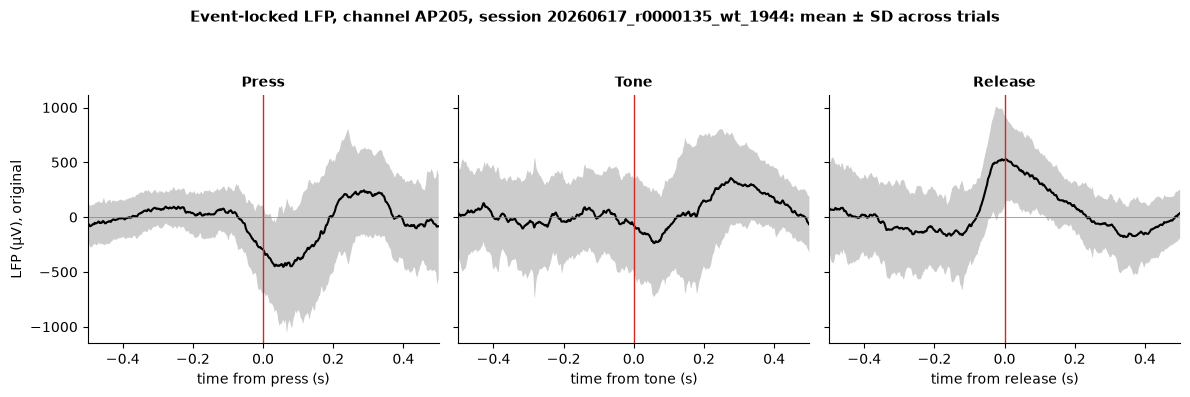

In [10]:
# %%
# ── 8. EXAMPLE ERP FIGURE: one channel, mean ± SD across trials (original), best session ──
SES = "20260617_r0000135_wt_1944"
EV_WIN = {"Press": (0.0, 0.4), "Tone": (0.0, 0.3), "Release": (-0.1, 0.3)}    # response windows, to pick the channel
BASE, XL = (-0.5, -0.1), (-0.5, 0.5)

# 1. best channel of this session (from the saved mean ERPs)
z = np.load(os.path.join(PROC, SES, "amir_data", "ERP", "erps.npz")); t0 = z["times"]; bm = (t0 >= BASE[0]) & (t0 <= BASE[1])
snr = [np.nanmax(np.abs(z[f"original__{ev}"][(t0 >= a) & (t0 <= b)]), axis=0) / np.nanstd(z[f"original__{ev}"][bm], axis=0)
       for ev, (a, b) in EV_WIN.items()]
CH = str(z["channel_ids"][int(np.nanargmax(np.min(np.vstack(snr), axis=0)))])

# 2. ERP of that channel from the recording, with SD across trials (same events as the event check)
rec = fn.load_session(PROC, SES, XB, refs=("original",))[0]["original"]
TRk = pd.read_csv(os.path.join(TABLES, "trials_filtered.csv"), dtype={"rat": str}, low_memory=False)
tr = TRk[TRk["keep"] & (TRk["session"] == SES)]
ev_t = {"Press": tr["press_neural_s"].values,
        "Tone": tr.loc[tr["label"].isin(["correct", "late"]), "tone_neural_s"].values,
        "Release": tr["release_neural_s"].values}
fig, axs = plt.subplots(1, 3, figsize=(12, 4), facecolor="white", sharey=True)
for ax, (ev, ts) in zip(axs, ev_t.items()):
    e = fn.event_erp(rec, ts, channel_ids=[CH], tmin=XL[0], tmax=XL[1])
    m = e["mean"][:, 0]; sd = e["sem"][:, 0] * np.sqrt(e["n"])
    ax.fill_between(e["times"], m - sd, m + sd, color="0.8", lw=0)
    ax.plot(e["times"], m, color="k", lw=1.5)
    ax.axvline(0, color="#d62728", lw=1); ax.axhline(0, color="0.5", lw=0.5)
    ax.set_xlim(*XL); ax.set_xlabel(f"time from {ev.lower()} (s)")
    ax.set_title(ev, fontsize=10, fontweight="bold")
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
axs[0].set_ylabel("LFP (µV), original")
fig.suptitle(f"Event-locked LFP, channel {CH.split('#')[-1]}, session {SES}: mean ± SD across trials", fontsize=11, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
ERP_DIR = os.path.join(r"O:\archive\projects\2020_euSNN\Neuropixels_RT_mPFC\data\amir_data", "ERP")
os.makedirs(ERP_DIR, exist_ok=True)
fig.savefig(os.path.join(ERP_DIR, f"ERP press tone release {SES} {CH.split('#')[-1]}.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()

Press: peak-to-peak 0–0.4 s, full ERP 697 µV | {'delta': '655 µV', 'theta': '68 µV', 'alpha': '45 µV', 'beta': '53 µV'}
Tone: peak-to-peak 0–0.4 s, full ERP 593 µV | {'delta': '409 µV', 'theta': '86 µV', 'alpha': '65 µV', 'beta': '54 µV'}
Release: peak-to-peak 0–0.4 s, full ERP 711 µV | {'delta': '576 µV', 'theta': '153 µV', 'alpha': '52 µV', 'beta': '26 µV'}


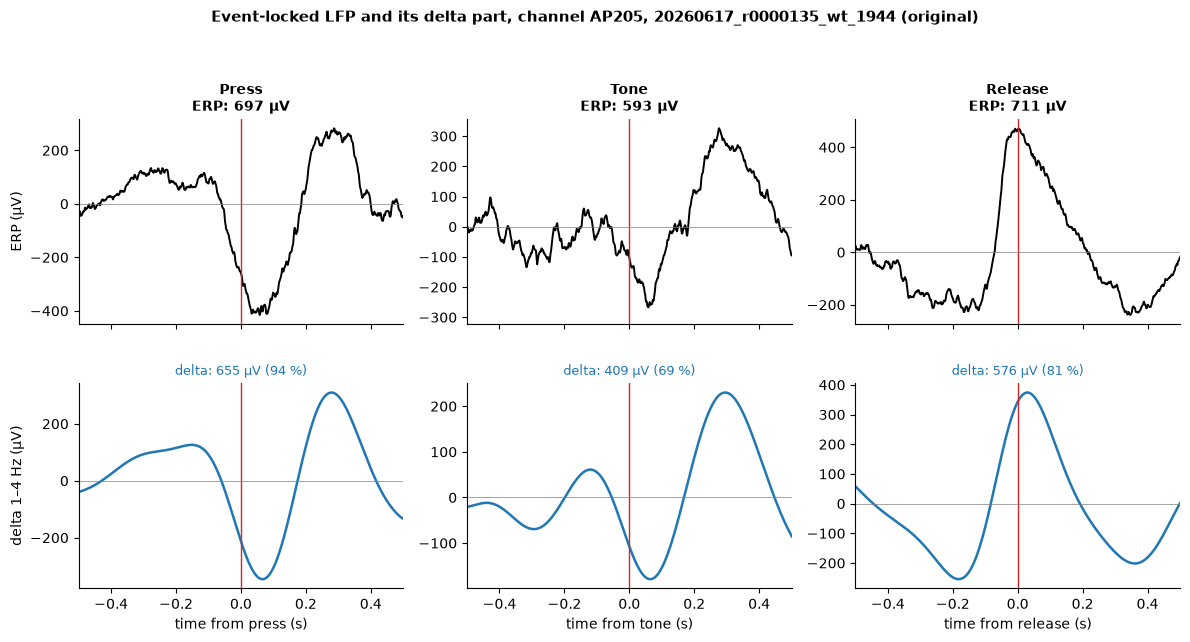

In [11]:
# %%
# ── ERP and its delta part (1–4 Hz), example channel, with sizes ──
import scipy.signal as ss
BANDS = {"delta": (1, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (15, 30)}
fig, axs = plt.subplots(2, 3, figsize=(12, 6.5), facecolor="white", sharex=True)
for j, (ev, ts) in enumerate(ev_t.items()):
    e = fn.event_erp(rec, ts, channel_ids=[CH], tmin=-1.0, tmax=1.0)                 # longer epoch for clean filtering
    m, tt = e["mean"][:, 0], e["times"]; fs = 1 / np.median(np.diff(tt))
    bp = {bn: ss.sosfiltfilt(ss.butter(3, [lo, hi], btype="bandpass", fs=fs, output="sos"), m) for bn, (lo, hi) in BANDS.items()}
    d = bp["delta"]
    win = (tt >= 0) & (tt <= 0.4)                                                     # 0–0.4 s after the event
    p_all, p_del = np.ptp(m[win]), np.ptp(d[win])
    axs[0, j].plot(tt, m, color="k", lw=1.4)
    axs[1, j].plot(tt, d, color="#1f77b4", lw=1.8)
    axs[0, j].set_title(f"{ev}\nERP: {p_all:.0f} µV", fontsize=10, fontweight="bold")
    axs[1, j].set_title(f"delta: {p_del:.0f} µV ({100 * p_del / p_all:.0f} %)", fontsize=9, color="#1f77b4")
    axs[1, j].set_xlabel(f"time from {ev.lower()} (s)")
    print(f"{ev}: peak-to-peak 0–0.4 s, full ERP {p_all:.0f} µV |",
          {bn: f"{np.ptp(v[win]):.0f} µV" for bn, v in bp.items()})
for a in axs.ravel():
    a.axvline(0, color="#d62728", lw=1); a.axhline(0, color="0.5", lw=0.5); a.set_xlim(-0.5, 0.5)
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
axs[0, 0].set_ylabel("ERP (µV)"); axs[1, 0].set_ylabel("delta 1–4 Hz (µV)")
fig.suptitle(f"Event-locked LFP and its delta part, channel {CH.split('#')[-1]}, {SES} (original)", fontsize=11, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94), h_pad=2.5)
fig.savefig(os.path.join(ERP_DIR, f"ERP and delta {SES} {CH.split('#')[-1]}.png"), dpi=300, facecolor="white", bbox_inches="tight")
plt.show()